# Run v7 locally: smoke test, every sweep, merge, quick look

This notebook runs the whole v7 pipeline on this machine (same steps as `run_v6.ipynb`):

1. **Smoke test** (`run_smoke.py`, ends with `RESULT: ALL PASS`).
2. **Every sweep** of `design.py`, in parallel: each sweep is split into `N_JOBS` shards and every
   shard runs `generate.py run` as its own process (the same command a cluster job runs).
   Finished runs are skipped, so an interrupted notebook can simply be re-run.
3. **Merge + hash** each sweep (`manifest.csv`, `groups.csv`, `hashes.csv`).
4. **Overview and quick-look figures** from the merged manifests.

Measured locally with 2 seeds and 8 parallel jobs: all five sweeps (1040 runs) took 96 seconds
and 136 MB, i.e. about **0.8 minutes and 68 MB per seed** with 8 jobs. 50 seeds (26,000 runs) is
then about 40 minutes and 3.4 GB; 100 seeds about 80 minutes and 7 GB.
Change the settings in the configuration cell below.

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path


def _find_root(start):
    for p in [start, *start.parents]:
        if (p / "marketsim").is_dir() and (p / "capstone codes").is_dir():
            return p
    raise RuntimeError("repository root not found above " + str(start))


ROOT = _find_root(Path.cwd().resolve())
V7 = ROOT / "capstone codes" / "washtrade" / "v7"
for p in (str(ROOT), str(ROOT / "capstone codes")):
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from washtrade.v7 import design as D
from washtrade.v7 import generate as G

print("repository root:", ROOT.name, "| python", sys.version.split()[0])

repository root: pymarketsim-master | python 3.12.5


## Configuration

In [2]:
SEEDS = 50                          # seeds 0..SEEDS-1 for every sweep
SWEEPS = list(D.SWEEPS)             # all five: scenarios, rotation, size, residual, evasive
N_JOBS = max(1, (os.cpu_count() or 2) - 1)   # parallel shard processes
OUT = V7 / "data"                   # datasets go to OUT / ds_v7_<sweep>  (git-ignored)
RUN_SMOKE = True                    # run the smoke test first
FORCE = False                       # True = regenerate runs that are already finished

n_runs = sum(len(D.enumerate_runs(sw, seeds=SEEDS)) for sw in SWEEPS)
print(f"{SEEDS} seeds, {N_JOBS} parallel jobs, {n_runs} runs, sweeps: {SWEEPS}")

50 seeds, 15 parallel jobs, 26000 runs, sweeps: ['scenarios', 'rotation', 'size', 'residual', 'evasive']


## 1. Smoke test

In [3]:
if RUN_SMOKE:
    t0 = time.time()
    res = subprocess.run([sys.executable, str(V7 / "run_smoke.py")], cwd=ROOT,
                         capture_output=True, text=True, encoding="utf-8")
    lines = res.stdout.splitlines()
    fails = [l for l in lines if "[FAIL]" in l]
    print(f"{sum('[PASS]' in l for l in lines)} checks passed, {len(fails)} failed "
          f"({time.time() - t0:.0f}s)")
    print("\n".join(fails + lines[-1:]))
    if res.returncode != 0:
        print(res.stderr[-3000:])
        raise RuntimeError("smoke test failed: fix this before generating data")

100 checks passed, 0 failed (25s)
RESULT: ALL PASS


## 2. Generate every sweep

Each shard's output goes to `OUT/logs/<sweep>_shard<i>.log`. A failed run leaves a traceback in
`OUT/ds_v7_<sweep>/errors/` and is retried the next time this cell runs.

In [4]:
def run_sweep_parallel(sweep, seeds=SEEDS, n_jobs=N_JOBS, out=OUT, force=FORCE):
    logs = Path(out) / "logs"
    logs.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    procs = []
    for i in range(n_jobs):
        cmd = [sys.executable, str(V7 / "generate.py"), "run", "--sweep", sweep,
               "--seeds", str(seeds), "--shard", str(i), "--n-shards", str(n_jobs),
               "--out", str(out)] + (["--force"] if force else [])
        fh = open(logs / f"{sweep}_shard{i}.log", "w", encoding="utf-8")
        procs.append((subprocess.Popen(cmd, cwd=ROOT, stdout=fh, stderr=subprocess.STDOUT), fh))
    codes = []
    for p, fh in procs:
        codes.append(p.wait())
        fh.close()
    man = G.merge(sweep, out_dir=str(out), verbose=False)
    G.hash_runs(sweep, out_dir=str(out), verbose=False)
    root = Path(G.dataset_root(sweep, out_dir=str(out)))
    n_err = len(list((root / "errors").glob("*.txt"))) if (root / "errors").exists() else 0
    print(f"{sweep:10s} {len(man):5d}/{len(D.enumerate_runs(sweep, seeds=seeds))} runs  "
          f"errors {n_err}  shard exit codes {sorted(set(codes))}  ({time.time() - t0:.0f}s)")
    return man


t_all = time.time()
manifests = {sw: run_sweep_parallel(sw) for sw in SWEEPS}
print(f"all sweeps done in {(time.time() - t_all) / 60:.1f} min")

scenarios   3000/3000 runs  errors 0  shard exit codes [0]  (358s)
rotation    3600/3600 runs  errors 0  shard exit codes [0]  (360s)
size        2100/2100 runs  errors 0  shard exit codes [0]  (221s)
residual    2700/2700 runs  errors 0  shard exit codes [0]  (283s)
evasive    14600/14600 runs  errors 0  shard exit codes [0]  (1283s)
all sweeps done in 41.7 min


## 3. Overview

In [5]:
def folder_mb(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file()) / 2**20


rows = []
for sw in SWEEPS:
    root = Path(G.dataset_root(sw, out_dir=str(OUT)))
    man = pd.read_csv(root / "manifest.csv")
    rows.append(dict(sweep=sw, runs_design=len(pd.read_csv(root / "design.csv")),
                     runs_complete=len(man), cells=man["cell"].nunique(),
                     export=man["mode"].iloc[0] if len(man) else "",
                     sim_minutes=round(man["sim_seconds"].sum() / 60, 1),
                     size_mb=round(folder_mb(root), 1)))
overview = pd.DataFrame(rows).set_index("sweep")
overview.loc["total", ["runs_design", "runs_complete", "cells", "sim_minutes", "size_mb"]] = (
    overview[["runs_design", "runs_complete", "cells", "sim_minutes", "size_mb"]].sum())
overview

,runs_design,runs_complete,cells,export,sim_minutes,size_mb
sweep,,,,,,
scenarios,3000.0,3000.0,60.0,slim,23.8,780.5
rotation,3600.0,3600.0,72.0,tape,19.8,302.0
size,2100.0,2100.0,42.0,tape,12.6,172.0
residual,2700.0,2700.0,54.0,tape,17.6,219.5
evasive,14600.0,14600.0,292.0,tape,109.4,1388.3
total,26000.0,26000.0,520.0,NaN,183.2,2862.3


## 4. Quick look

Seed means with 95% intervals (mean ± 1.96 standard errors across seeds). Colours follow the
background, in a fixed order: thin, thick, active, active_dense. Solid and dashed lines are named
in each legend.

In [6]:
BG_ORDER = ["thin", "thick", "active", "active_dense"]
BG_COLOR = {"thin": "#2a78d6", "thick": "#eb6834", "active": "#1baf7a",
            "active_dense": "#eda100"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 5,
})


def load(sw, file="manifest.csv"):
    return pd.read_csv(Path(G.dataset_root(sw, out_dir=str(OUT))) / file)


def mean_ci(df, by, col):
    out = df.groupby(by)[col].agg(["mean", "std", "count"]).reset_index()
    out["half"] = 1.96 * out["std"].fillna(0) / np.sqrt(out["count"])
    return out


def line_ci(ax, d, x, label, color, ls="-"):
    d = d.sort_values(x)
    ax.plot(d[x], d["mean"], ls, color=color, marker="o", label=label)
    ax.fill_between(d[x], d["mean"] - d["half"], d["mean"] + d["half"], color=color,
                    alpha=0.15, linewidth=0)

### Rotation: how often the same pair trades, and how often a wash wallet returns to zero

Triad cycles (solid) and dyad cycles (dashed) drawn from pools of growing size; gap 0. The
leftmost point of each line is the fixed group (pool = cycle length, as in v6).

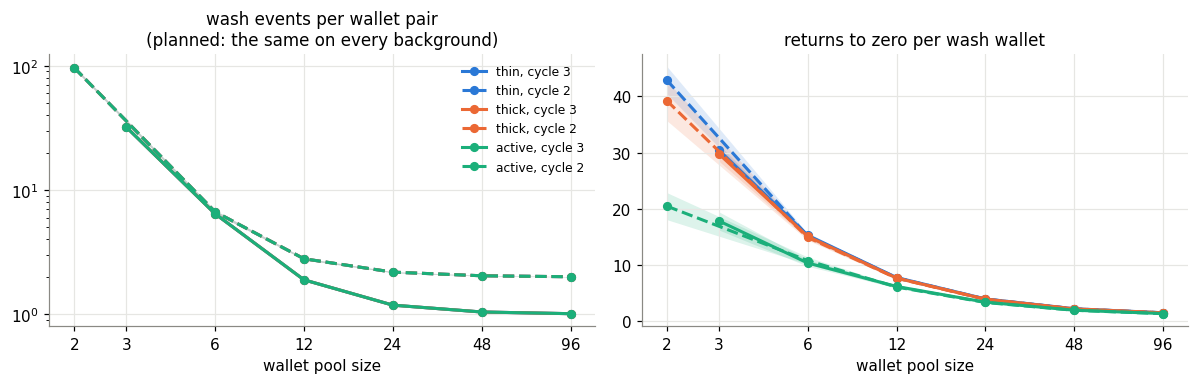

In [7]:
rt = load("rotation")
rt = rt[rt.f_gap == 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (col, title) in zip(axes, [("events_per_pair_mean", "wash events per wallet pair\n(planned: the same on every background)"),
                                   ("zero_returns_per_used_wallet", "returns to zero per wash wallet")]):
    for b in BG_ORDER:
        for k, ls in ((3, "-"), (2, "--")):
            sub = rt[(rt.f_background == b) & (rt.f_cycle_len == k)]
            if len(sub):
                line_ci(ax, mean_ci(sub, "f_pool", col), "f_pool", f"{b}, cycle {k}", BG_COLOR[b], ls)
    ax.set_xscale("log")
    ax.minorticks_off()
    pools = sorted(rt.f_pool.unique())
    ax.set_xticks(pools, [str(int(p)) for p in pools])
    ax.set_xlabel("wallet pool size")
    ax.set_title(title)
axes[0].set_yscale("log")
axes[0].legend(fontsize=8)
fig.tight_layout()

### Size: round size Q uniform on 1..hi

Solid: Q unit events (every leg has quantity 1, like the ZI background). Dashed: one event of
quantity Q ("block"), whose legs are visible on the tape as qty > 1. Gap 0.

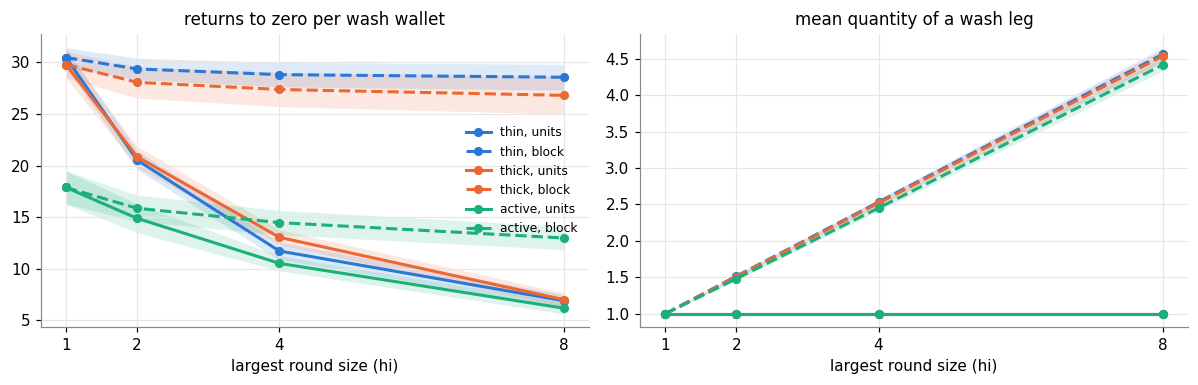

In [8]:
sz = load("size")
sz = sz[sz.f_gap == 0]
groups_sz = load("size", "groups.csv")
groups_sz = groups_sz[groups_sz.f_gap == 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (df, col, title) in zip(axes, [(sz, "zero_returns_per_used_wallet", "returns to zero per wash wallet"),
                                       (groups_sz, "mean_wash_leg_qty", "mean quantity of a wash leg")]):
    for b in BG_ORDER:
        for ex, ls in (("units", "-"), ("block", "--")):
            sub = df[(df.f_background == b) & ((df.f_size_exec == ex) | (df.f_q_hi == 1))]
            if len(sub):
                line_ci(ax, mean_ci(sub, "f_q_hi", col), "f_q_hi", f"{b}, {ex}", BG_COLOR[b], ls)
    ax.set_xticks([1, 2, 4, 8])
    ax.set_xlabel("largest round size (hi)")
    ax.set_title(title)
axes[0].legend(fontsize=8)
fig.tight_layout()

### Residual: the closing edge is off by up to d units with probability p

Solid: d = 1; dashed: d = 2. Left: at the end of every completed round, share of its members whose
realized position is not zero (a run usually stops mid-round, so the final position would mislead).
Right: returns to zero per wash wallet. Gap 0; p = 0 is the same group without residuals.

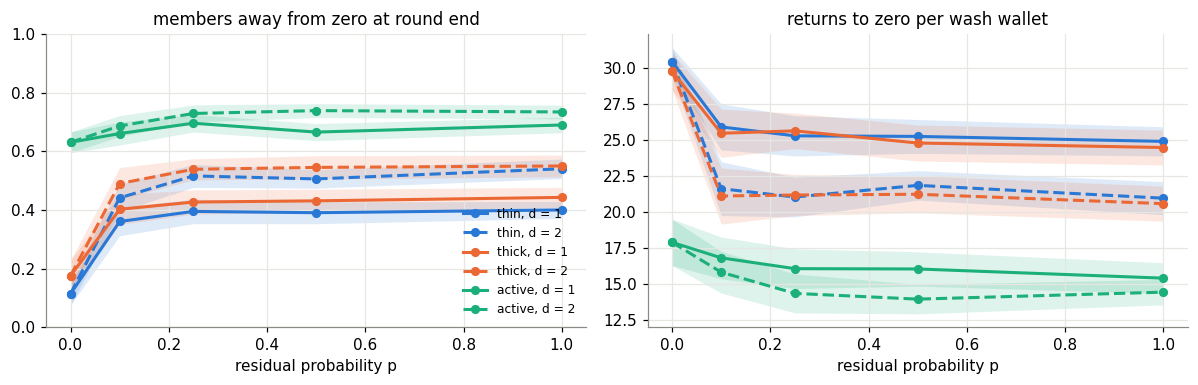

In [9]:
rs = load("residual")
rs = rs[rs.f_gap == 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (df, col, title) in zip(axes, [(rs, "round_end_nonzero_share", "members away from zero at round end"),
                                       (rs, "zero_returns_per_used_wallet", "returns to zero per wash wallet")]):
    for b in BG_ORDER:
        for d, ls in ((1, "-"), (2, "--")):
            sub = df[(df.f_background == b) & ((df.f_residual_max == d) | (df.f_residual_prob == 0))]
            if len(sub):
                line_ci(ax, mean_ci(sub, "f_residual_prob", col), "f_residual_prob",
                        f"{b}, d = {d}", BG_COLOR[b], ls)
    ax.set_xlabel("residual probability p")
    ax.set_title(title)
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout()

### Evasive factorial (gap 0, no camouflage; seed means)

For comparison, the first line prints how often an honest agent's position returns to zero in
the control run of each background.

In [10]:
ev = load("evasive")
ctrl = ev[ev.f_scenario == "control"].groupby("f_background")["honest_zero_returns_per_agent"].mean()
print("honest zero returns per agent (control):", ctrl.round(2).to_dict())
w = ev[(ev.f_scenario == "wash") & (ev.f_gap == 0) & (ev.f_camouflage_total == 0)]
cols = ["events_per_pair_mean", "zero_returns_per_used_wallet", "round_end_nonzero_share",
        "leak_prorata", "wash_leg_volume_share"]
pd.set_option("display.max_rows", 200)
w.groupby(["f_background", "f_pool", "f_q_hi", "f_residual_prob"])[cols].mean().round(2)

honest zero returns per agent (control): {'active': 3.39, 'active_dense': 3.37, 'thick': 0.49, 'thin': 0.25}


events_per_pair_mean  \
f_background f_pool f_q_hi f_residual_prob                         
active       3.0    1.0    0.0                             32.15   
                           0.5                             32.15   
                    4.0    0.0                             32.15   
                           0.5                             32.15   
             12.0   1.0    0.0                              1.89   
                           0.5                              1.97   
                    4.0    0.0                              3.34   
                           0.5                              3.39   
             96.0   1.0    0.0                              1.01   
                           0.5                              1.10   
                    4.0    0.0                              2.56   
                           0.5                              2.61   
active_dense 3.0    1.0    0.0                             32.15   
                           0.5                             32.15   
                    4.0    0.0                             32.15   
                           0.5                             32.15   
             12.0   1.0    0.0                              1.89   
                           0.5                              1.97   
                    4.0    0.0                              3.34   
                           0.5                              3.39   
             96.0   1.0    0.0                              1.01   
                           0.5                              1.10   
                    4.0    0.0                              2.56   
                           0.5                              2.61   
thick        3.0    1.0    0.0                             32.15   
                           0.5                             32.15   
                    4.0    0.0                             32.15   
                           0.5                             32.15   
             12.0   1.0    0.0                              1.89   
                           0.5                              1.97   
                    4.0    0.0                              3.34   
                           0.5                              3.39   
             96.0   1.0    0.0                              1.01   
                           0.5                              1.10   
                    4.0    0.0                              2.56   
                           0.5                              2.61   
thin         3.0    1.0    0.0                             32.15   
                           0.5                             32.15   
                    4.0    0.0                             32.15   
                           0.5                             32.15   
             12.0   1.0    0.0                              1.89   
                           0.5                              1.97   
                    4.0    0.0                              3.34   
                           0.5                              3.39   
             96.0   1.0    0.0                              1.01   
                           0.5                              1.10   
                    4.0    0.0                              2.56   
                           0.5                              2.61   

                                            zero_returns_per_used_wallet  \
f_background f_pool f_q_hi f_residual_prob                                 
active       3.0    1.0    0.0                                     17.87   
                           0.5                                     16.02   
                    4.0    0.0                                     10.53   
                           0.5                                     10.15   
             12.0   1.0    0.0                                      6.22   
                           0.5                                      5.09   
                    4.0    0.0     

### Named scenarios on every background (seed means)

In [11]:
sc = load("scenarios")
cols = ["self_trade_rate", "wash_leg_volume_share", "leak_prorata", "n_pairs",
        "events_per_pair_mean", "zero_returns_per_used_wallet"]
sc.groupby(["f_background", "f_scenario"])[cols].mean().round(2)

self_trade_rate  wash_leg_volume_share  \
f_background f_scenario                                                 
active       control                       NaN                   0.00   
             dyad                         0.81                   0.22   
             evasive_camo                 0.79                   0.20   
             triad                        0.81                   0.22   
             triad_block4                 0.81                   0.43   
             triad_evasive                0.81                   0.22   
             triad_evasive_g5             0.45                   0.17   
             triad_gap5                   0.45                   0.17   
             triad_pool12                 0.81                   0.22   
             triad_pool96                 0.81                   0.22   
             triad_res                    0.81                   0.22   
             triad_size4                  0.81                   0.22   
active_dense control                       NaN                   0.00   
             dyad                         0.68                   0.12   
             evasive_camo                 0.65                   0.11   
             triad                        0.68                   0.12   
             triad_block4                 0.68                   0.27   
             triad_evasive                0.68                   0.12   
             triad_evasive_g5             0.25                   0.09   
             triad_gap5                   0.25                   0.09   
             triad_pool12                 0.68                   0.12   
             triad_pool96                 0.68                   0.12   
             triad_res                    0.68                   0.12   
             triad_size4                  0.68                   0.12   
active_thin  control                       NaN                   0.00   
             dyad                         0.97                   0.72   
             evasive_camo                 0.95                   0.56   
             triad                        0.97                   0.72   
             triad_block4                 0.97                   0.87   
             triad_evasive                0.97                   0.73   
             triad_evasive_g5             0.88                   0.67   
             triad_gap5                   0.88                   0.67   
             triad_pool12                 0.97                   0.72   
             triad_pool96                 0.97                   0.73   
             triad_res                    0.97                   0.72   
             triad_size4                  0.97                   0.72   
thick        control                       NaN                   0.00   
             dyad                         0.97                   0.60   
             evasive_camo                 0.95                   0.53   
             triad                        0.97                   0.60   
             triad_block4                 0.97                   0.79   
             triad_evasive                0.97                   0.60   
             triad_evasive_g5             0.81                   0.53   
             triad_gap5                   0.81                   0.53   
             triad_pool12                 0.97                   0.60   
             triad_pool96                 0.97                   0.61   
             triad_res                    0.97                   0.60   
             triad_size4                  0.97                   0.60   
thin         control                       NaN                   0.00   
             dyad                         0.99                   0.87   
             evasive_camo                 0.98                   0.74   
             triad                        0.99                   0.87   
             triad_block4                 0.99                   0.94   
             tri